# plot development of "tas" over time of the simulation
- input: annual/data (annual means) (70_x)
- output: plot with annual means of tas plotted against year 

In [1]:
import os 
import pickle
import numpy as np
import xarray as xr
import pandas as pd
from pathlib import Path


In [2]:
output_directory = Path("../output/plots/dev/")
output_file = "tas_scatterplot_per_year.pdf"

# input
inputdir = Path("../output/annual/data")

datasets = ["cell_tracks", "cell_features", "anvil_features", "domain"]

Tsmean = {}
Tsci_low = {}
Tsci_high = {}
Tsboot = {}

for dataset in datasets:
    filepath = os.path.join(
        inputdir,
        f"yearly_stats_abso_boot_{dataset}.pkl")
    with open(filepath, "rb") as f:
        ds_annual = pickle.load(f)

    Tsmean[dataset] = ds_annual["mean"][
        [v for v in ds_annual["mean"].data_vars if "tas" in v]]
    Tsci_low[dataset] = ds_annual["ci_low"][
        [v for v in ds_annual["ci_low"].data_vars if "tas" in v]]
    Tsci_high[dataset] = ds_annual["ci_high"][
        [v for v in ds_annual["ci_high"].data_vars if "tas" in v]]
    Tsboot[dataset] = ds_annual["boot"][
        [v for v in ds_annual["boot"].data_vars if "tas" in v]]

/tmp/ipykernel_2471403/2407413582.py:35: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  sc = plt.scatter(x_data, data,


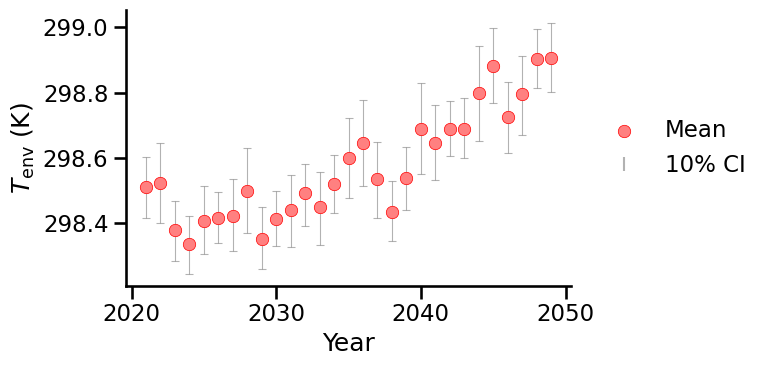

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

sns.set_context("talk")

x_data = Tsmean["cell_tracks"]["year"].values
data = Tsmean["cell_tracks"]["tas_cell_mean"].values
annual_mean_alpha = 10
data_low = Tsci_low["cell_tracks"]["tas_cell_mean"].values
data_upper = Tsci_high["cell_tracks"]["tas_cell_mean"].values

# Compute y-axisdataerror bars (variable CI), if available
y_err_low  = data - data_low
y_err_high = data_upper  - data
yerr = np.array([y_err_low, y_err_high])

colorred = "#FF8080"   


# Error bars (plotted before scatter so dots sit on top)
plt.errorbar(
    x_data, data,
    yerr=yerr,
    fmt='none',          # no marker bc scatter draws those below
    ecolor='grey',
    elinewidth=0.8,
    capsize=3,
    capthick=0.8,
    alpha=0.6,
    zorder=4,
)
# Dots colored by year
sc = plt.scatter(x_data, data,
                c=colorred,   # already sorted
                 edgecolors="red",
                 linewidths = 0.5,
                 cmap='viridis_r' ,#'cividis_r',
                 s=80, zorder=5)


# legend of lines
legend_handles = []

        
legend_handles.append(
    plt.scatter([], [], c=colorred, edgecolors="red",linewidths = 0.5,s=80, label='Mean'))
    
if data_low is not None and data_upper is not None:
    legend_handles.append(
        plt.Line2D([0], [0], color='grey', linewidth=0, linestyle='none',
                   marker='|', markersize=10, markeredgewidth=1.5,
                   alpha=0.6, label=f'{annual_mean_alpha}% CI') )
    
if legend_handles:
    # plt.legend(handles=legend_handles, loc='best', frameon=True)
    plt.subplots_adjust(right=0.75)
    plt.legend(handles=legend_handles,
               loc='center left',
               bbox_to_anchor=(1.02, 0.5),
               ncol=1,
               frameon=False)
# plots format
sns.despine(right=True, top=True)
plt.title("")
plt.xlabel(f'Year')
plt.ylabel(r"$T_{\mathrm{env}}$ (K)")
#plt.xticks(rotation=45)
plt.tight_layout()


# save 

plt.savefig(
    os.path.join(output_directory, output_file),
    dpi=300,
    bbox_inches="tight"
)
plt.show()